In [1]:
import kagglehub
import os
import matplotlib.pyplot as plt
from PIL import Image

path = kagglehub.dataset_download("mariaherrerot/aptos2019")

print("Dataset path:", path)
print("Files:", os.listdir(path))

Using Colab cache for faster access to the 'aptos2019' dataset.
Dataset path: /kaggle/input/aptos2019
Files: ['val_images', 'train_images', 'valid.csv', 'test.csv', 'train_1.csv', 'test_images']


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import timm
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, roc_auc_score, classification_report
import numpy as np

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [3]:
import pandas as pd
csv_path_1 = os.path.join(path, "train_1.csv")
image_dir = os.path.join(path, "train_images", "train_images")
df = pd.read_csv(csv_path_1)
print(df.head())


        id_code  diagnosis
0  1ae8c165fd53          2
1  1b329a127307          1
2  1b32e1d775ea          4
3  1b3647865779          0
4  1b398c0494d1          0


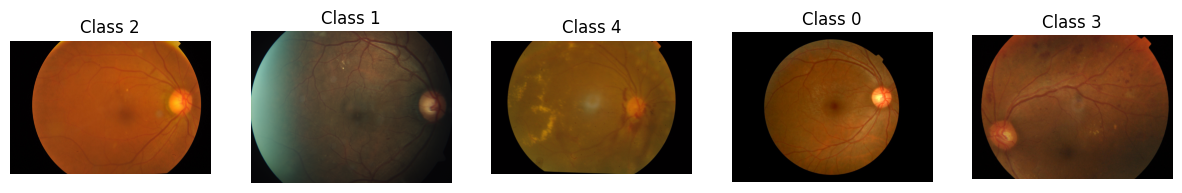

In [4]:

# Get one sample per class
classes = df['diagnosis'].unique()
sample_images = {}

for cls in classes:
    # Take the first occurrence of each class
    sample_row = df[df['diagnosis'] == cls].iloc[0]
    sample_images[cls] = sample_row['id_code']

# Plot images
plt.figure(figsize=(15, 5))
for i, (cls, img_id) in enumerate(sample_images.items()):
    img_path = os.path.join(image_dir, f"{img_id}.png")  # assuming images are .png
    img = Image.open(img_path)

    plt.subplot(1, len(sample_images), i + 1)
    plt.imshow(img)
    plt.title(f"Class {cls}")
    plt.axis('off')

plt.show()

In [5]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df, test_size=0.2, stratify=df['diagnosis'], random_state=42
)


In [6]:
def cr_f(base):
    for i in range(5):
        os.makedirs(f"{base}/{i}", exist_ok=True)
cr_f("data/train")
cr_f("data/val")


In [7]:
import shutil

def copy_images(dataframe, dest):
    c = 0
    m= 0

    for _, row in dataframe.iterrows():
        found = False

        for ext in [".png", ".jpeg", ".jpg"]:
            src = os.path.join(image_dir, row['id_code'] + ext)

            if os.path.exists(src):
                dst = f"{dest}/{row['diagnosis']}/{row['id_code']}{ext}"
                shutil.copy(src, dst)
                c += 1
                found = True
                break

        if not found:
            m += 1

    print(f"{dest} -> Copied: {c}, Missing: {m}")


copy_images(train_df, "data/train")
copy_images(val_df, "data/val")

data/train -> Copied: 2344, Missing: 0
data/val -> Copied: 586, Missing: 0


In [8]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

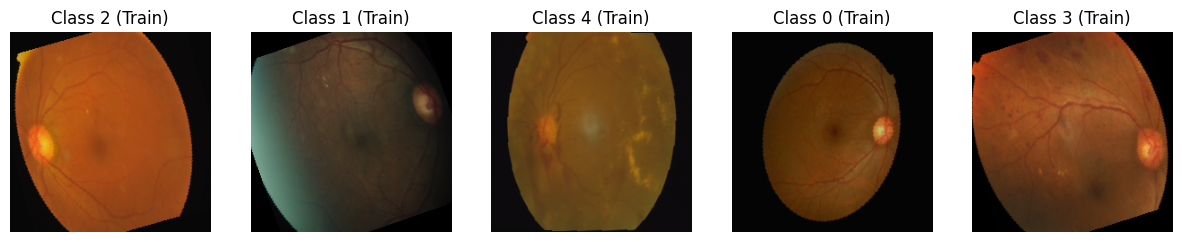

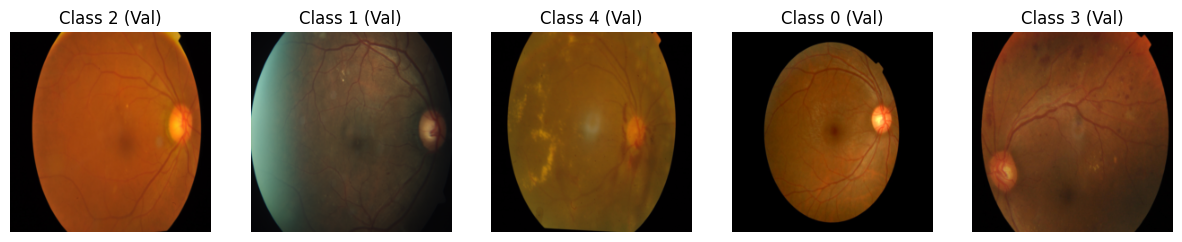

In [9]:
# Function to unnormalize for visualization
def unnormalize(img_tensor):
    img_tensor = img_tensor.clone()
    img_tensor = img_tensor * torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img_tensor = img_tensor + torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    img_tensor = img_tensor.clamp(0,1)
    return img_tensor

# Get one sample per class
classes = df['diagnosis'].unique()
sample_images = {}

for cls in classes:
    sample_row = df[df['diagnosis'] == cls].iloc[0]
    sample_images[cls] = sample_row['id_code']

# Visualize transformed images (train_transform)
plt.figure(figsize=(15,5))
for i, (cls, img_id) in enumerate(sample_images.items()):
    img_path = os.path.join(image_dir, f"{img_id}.png")  # adjust extension
    img = Image.open(img_path).convert("RGB")

    img_transformed = train_transform(img)  # apply train transform
    img_transformed = unnormalize(img_transformed)  # undo normalization for visualization

    plt.subplot(1, len(sample_images), i+1)
    plt.imshow(img_transformed.permute(1,2,0))  # C,H,W -> H,W,C
    plt.title(f"Class {cls} (Train)")
    plt.axis('off')
plt.show()

# Visualize transformed images (val_transform)
plt.figure(figsize=(15,5))
for i, (cls, img_id) in enumerate(sample_images.items()):
    img_path = os.path.join(image_dir, f"{img_id}.png")
    img = Image.open(img_path).convert("RGB")

    img_transformed = val_transform(img)
    img_transformed = unnormalize(img_transformed)

    plt.subplot(1, len(sample_images), i+1)
    plt.imshow(img_transformed.permute(1,2,0))
    plt.title(f"Class {cls} (Val)")
    plt.axis('off')
plt.show()

In [10]:

train_data = datasets.ImageFolder("data/train", transform=train_transform)
val_data = datasets.ImageFolder("data/val", transform=val_transform)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader = DataLoader(val_data, batch_size=16)

In [11]:
labels = [label for _, label in train_data.samples]
class_counts = np.bincount(labels)

class_weights_data= 1. / class_counts
class_weights_data = torch.tensor(class_weights_data, dtype=torch.float).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_data)



vit = timm.create_model('vit_base_patch16_224', pretrained=True)
vit.head = nn.Linear(vit.head.in_features, 5)

resnet = models.resnet50(pretrained=True)
resnet.fc = nn.Linear(resnet.fc.in_features, 5)

vit = vit.to(DEVICE)
resnet = resnet.to(DEVICE)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 186MB/s]


In [12]:
vit_opt = optim.Adam(vit.parameters(), lr=1e-4)
resnet_opt = optim.Adam(resnet.parameters(), lr=1e-4)


In [13]:
for name, param in vit.named_parameters():
    if "head" not in name:  # Unfreeze the head layer
        param.requires_grad = False

for name, param in resnet.named_parameters():
    if "fc" not in name:  # Unfreeze the fc layer
        param.requires_grad = False

In [14]:
def train(model, optimizer):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss


In [15]:
def evaluate(model):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            outputs = model(images)

            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)

            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
            all_probs.extend(probs)

    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    weighted_f1 = f1_score(all_labels, all_preds, average='weighted')

    try:
        auc = roc_auc_score(all_labels, all_probs, multi_class='ovr')
    except:
        auc = "Not computable"

    print("\nMacro F1:", macro_f1)
    print("Weighted F1:", weighted_f1)
    print("AUC-ROC:", auc)
    print("\nClassification Report:\n", classification_report(all_labels, all_preds))

In [16]:
for name, param in resnet.named_parameters():
    if "fc" not in name:
        param.requires_grad = False

In [21]:
import timm
import torchvision.models as models
num_classes = 5
vit = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=num_classes)
resnet = models.resnet50(pretrained=True)
resnet.fc = torch.nn.Linear(resnet.fc.in_features, num_classes)
swin_transformer = timm.create_model('swin_base_patch4_window7_224', pretrained=True, num_classes=num_classes) # New model: Swin Transformer

for name, param in vit.named_parameters():
    if "head" not in name:
        param.requires_grad = False

for name, param in resnet.named_parameters():
    if "fc" not in name:
        param.requires_grad = False

for name, param in swin_transformer.named_parameters(): # Unfreeze Swin Transformer head
    if "head" not in name:
        param.requires_grad = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vit = vit.to(device)
resnet = resnet.to(device)
swin_transformer = swin_transformer.to(device) # Move Swin Transformer to device


import torch.optim as optim
import torch.nn as nn
criterion = nn.CrossEntropyLoss()
vit_optimizer = optim.Adam(filter(lambda p: p.requires_grad, vit.parameters()), lr=1e-4)
resnet_optimizer = optim.Adam(filter(lambda p: p.requires_grad, resnet.parameters()), lr=1e-4)
swin_transformer_optimizer = optim.Adam(filter(lambda p: p.requires_grad, swin_transformer.parameters()), lr=1e-4) # New optimizer for Swin Transformer


epochs = 10
for epoch in range(epochs):
    vit.train()
    resnet.train()
    swin_transformer.train() # Set Swin Transformer to train mode
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        vit_optimizer.zero_grad()
        vit_outputs = vit(images);
        vit_loss = criterion(vit_outputs, labels)
        vit_loss.backward()
        vit_optimizer.step()

        resnet_optimizer.zero_grad()
        resnet_outputs = resnet(images);
        resnet_loss = criterion(resnet_outputs, labels)
        resnet_loss.backward()
        resnet_optimizer.step()

        swin_transformer_optimizer.zero_grad() # Swin Transformer training steps
        swin_transformer_outputs = swin_transformer(images);
        swin_transformer_loss = criterion(swin_transformer_outputs, labels)
        swin_transformer_loss.backward()
        swin_transformer_optimizer.step()

    print(f"Epoch {epoch+1}: ViT Loss={vit_loss.item():.4f}, ResNet Loss={resnet_loss.item():.4f}, Swin Transformer Loss={swin_transformer_loss.item():.4f}")

Epoch 1: ViT Loss=0.7055, ResNet Loss=0.9706, Swin Transformer Loss=1.0036
Epoch 2: ViT Loss=0.5307, ResNet Loss=0.8669, Swin Transformer Loss=0.7513
Epoch 3: ViT Loss=1.6714, ResNet Loss=1.3437, Swin Transformer Loss=1.1924
Epoch 4: ViT Loss=0.9421, ResNet Loss=1.2244, Swin Transformer Loss=1.2461
Epoch 5: ViT Loss=0.9351, ResNet Loss=0.6438, Swin Transformer Loss=0.6543
Epoch 6: ViT Loss=0.6569, ResNet Loss=0.7725, Swin Transformer Loss=0.6357
Epoch 7: ViT Loss=0.1447, ResNet Loss=0.5305, Swin Transformer Loss=0.2682
Epoch 8: ViT Loss=0.5777, ResNet Loss=0.5800, Swin Transformer Loss=0.6908
Epoch 9: ViT Loss=0.4184, ResNet Loss=0.7162, Swin Transformer Loss=0.5050
Epoch 10: ViT Loss=0.3747, ResNet Loss=0.5837, Swin Transformer Loss=0.3552


In [22]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

vit.eval()
resnet.eval()
swin_transformer.eval() # Set Swin Transformer to eval mode
vit_correct = 0
resnet_correct = 0
swin_transformer_correct = 0 # New counter for Swin Transformer
total = 0
vit_preds = []
resnet_preds = []
swin_transformer_preds = [] # New list for Swin Transformer
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        vit_outputs = vit(images)
        _, vit_pred = torch.max(vit_outputs, 1)
        resnet_outputs = resnet(images)
        _, resnet_pred = torch.max(resnet_outputs, 1)
        swin_transformer_outputs = swin_transformer(images) # Swin Transformer prediction
        _, swin_transformer_pred = torch.max(swin_transformer_outputs, 1) # Swin Transformer prediction

        total += labels.size(0)
        vit_correct += (vit_pred == labels).sum().item()
        resnet_correct += (resnet_pred == labels).sum().item()
        swin_transformer_correct += (swin_transformer_pred == labels).sum().item() # Update Swin Transformer correct count

        vit_preds.extend(vit_pred.cpu().numpy())
        resnet_preds.extend(resnet_pred.cpu().numpy())
        swin_transformer_preds.extend(swin_transformer_pred.cpu().numpy()) # Extend Swin Transformer preds
        all_labels.extend(labels.cpu().numpy())

vit_accuracy = vit_correct / total
resnet_accuracy = resnet_correct / total
swin_transformer_accuracy = swin_transformer_correct / total # Calculate Swin Transformer accuracy

print(f"\nViT Accuracy: {vit_accuracy:.4f}")
print(f"ResNet Accuracy: {resnet_accuracy:.4f}")
print(f"Swin Transformer Accuracy: {swin_transformer_accuracy:.4f}") # Print Swin Transformer accuracy


ViT Accuracy: 0.7423
ResNet Accuracy: 0.7270
Swin Transformer Accuracy: 0.7253


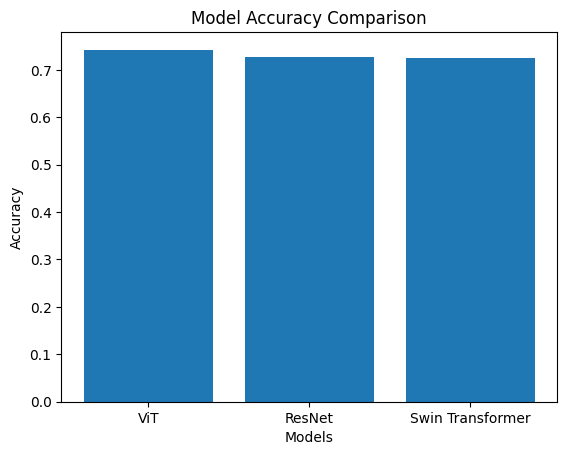

In [23]:
models = ['ViT', 'ResNet', 'Swin Transformer'] # Update models list
accuracies = [vit_accuracy, resnet_accuracy, swin_transformer_accuracy] # Update accuracies list

plt.figure()
plt.bar(models, accuracies)
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.show()